In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

print("Environment ready!")

Environment ready!


In [3]:
print("Contents of /kaggle/input:")

for item in os.listdir("/kaggle/input"):
    print(item)

Contents of /kaggle/input:
datasets


In [4]:
dataset_path = "/kaggle/input/datasets"

print("Contents of dataset folder:")

for item in os.listdir(dataset_path):
    print(item)

Contents of dataset folder:
ipythonx


In [5]:
dataset_path = "/kaggle/input/datasets/ipythonx"

print("Contents of ipythonx folder:")

for item in os.listdir(dataset_path):
    print(item)

Contents of ipythonx folder:
mvtec-ad


In [6]:
dataset_path = "/kaggle/input/datasets/ipythonx/mvtec-ad"

print("Contents of MVTec AD:")

for item in os.listdir(dataset_path):
    print(item)

Contents of MVTec AD:
wood
screw
metal_nut
capsule
readme.txt
hazelnut
carpet
pill
license.txt
grid
zipper
transistor
tile
leather
toothbrush
bottle
cable


In [7]:
bottle_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle"

print("Contents of bottle dataset:")

for item in os.listdir(bottle_path):
    print(item)

Contents of bottle dataset:
readme.txt
ground_truth
license.txt
test
train


In [8]:
train_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train"

print("Contents of bottle/train:")

for item in os.listdir(train_path):
    print(item)

Contents of bottle/train:
good


In [9]:
test_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test"

print("Contents of bottle/test:")

for item in os.listdir(test_path):
    print(item)

Contents of bottle/test:
good
contamination
broken_large
broken_small


In [10]:
ground_truth_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth"

print("Contents of bottle/ground_truth:")

for item in os.listdir(ground_truth_path):
    print(item)

Contents of bottle/ground_truth:
contamination
broken_large
broken_small


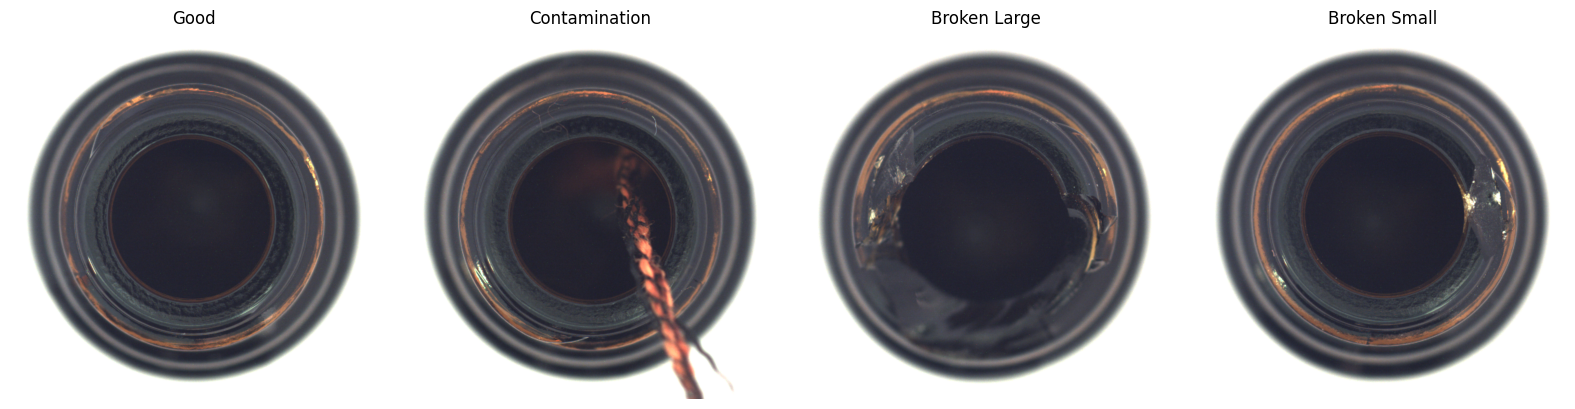

In [11]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Paths
good_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/good"
contamination_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/contamination"
broken_large_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_large"
broken_small_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_small"

# Get one image from each category
good_image = os.path.join(good_path, os.listdir(good_path)[0])
contamination_image = os.path.join(contamination_path, os.listdir(contamination_path)[0])
broken_large_image = os.path.join(broken_large_path, os.listdir(broken_large_path)[0])
broken_small_image = os.path.join(broken_small_path, os.listdir(broken_small_path)[0])

# Display images
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

images = [
    good_image,
    contamination_image,
    broken_large_image,
    broken_small_image
]

titles = [
    "Good",
    "Contamination",
    "Broken Large",
    "Broken Small"
]

for ax, image_path, title in zip(axes, images, titles):
    image = Image.open(image_path)
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Define the test dataset path
test_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test"

# Count images in each test category
categories = ["good", "contamination", "broken_large", "broken_small"]

for category in categories:
    category_path = os.path.join(test_path, category)
    
    image_files = [
        file for file in os.listdir(category_path)
        if file.lower().endswith((".png", ".jpg", ".jpeg"))
    ]
    
    print(f"{category}: {len(image_files)} images")

good: 20 images
contamination: 21 images
broken_large: 20 images
broken_small: 22 images


In [13]:
# Define the training dataset path
train_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train"

good_train_path = os.path.join(train_path, "good")

train_images = [
    file for file in os.listdir(good_train_path)
    if file.lower().endswith((".png", ".jpg", ".jpeg"))
]

print(f"Training images (good): {len(train_images)}")

Training images (good): 209


In [14]:
# Create dataset summary
import pandas as pd
dataset_summary = pd.DataFrame({
    "Split": [
        "Train",
        "Test",
        "Test",
        "Test",
        "Test"
    ],
    "Category": [
        "Good",
        "Good",
        "Contamination",
        "Broken Large",
        "Broken Small"
    ],
    "Number of Images": [
        len(train_images),
        20,
        21,
        20,
        22
    ]
})

dataset_summary

,Split,Category,Number of Images
0,Train,Good,209
1,Test,Good,20
2,Test,Contamination,21
3,Test,Broken Large,20
4,Test,Broken Small,22


In [15]:
# Define ground-truth path
import os
ground_truth_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth"

# Select defect category
mask_category = "broken_large"

# Create path to the selected mask category
mask_path = os.path.join(
    ground_truth_path,
    mask_category
)

# Find mask image files
mask_files = [
    file for file in os.listdir(mask_path)
    if file.lower().endswith((".png", ".jpg", ".jpeg"))
]

print(f"Number of {mask_category} masks: {len(mask_files)}")
print("Example mask:", mask_files[0])

Number of broken_large masks: 20
Example mask: 010_mask.png


Test image: 007.png
Ground-truth mask: 010_mask.png


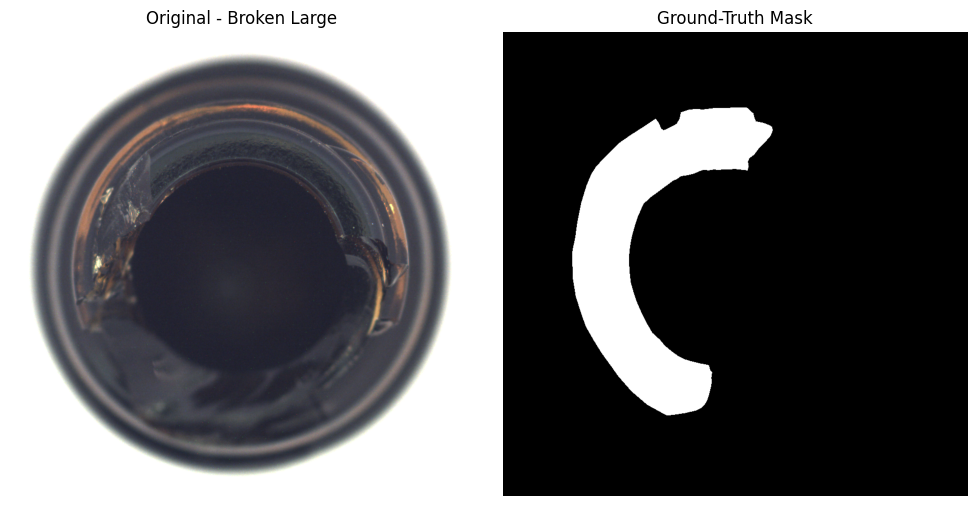

In [16]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Paths
test_defect_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_large"
ground_truth_defect_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large"

# Get one test image
test_files = [
    f for f in os.listdir(test_defect_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

# Get one ground-truth mask
mask_files = [
    f for f in os.listdir(ground_truth_defect_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

print("Test image:", test_files[0])
print("Ground-truth mask:", mask_files[0])

# Load images
test_image = Image.open(
    os.path.join(test_defect_path, test_files[0])
)

mask_image = Image.open(
    os.path.join(ground_truth_defect_path, mask_files[0])
)

# Display side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(test_image)
axes[0].set_title("Original - Broken Large")
axes[0].axis("off")

axes[1].imshow(mask_image, cmap="gray")
axes[1].set_title("Ground-Truth Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

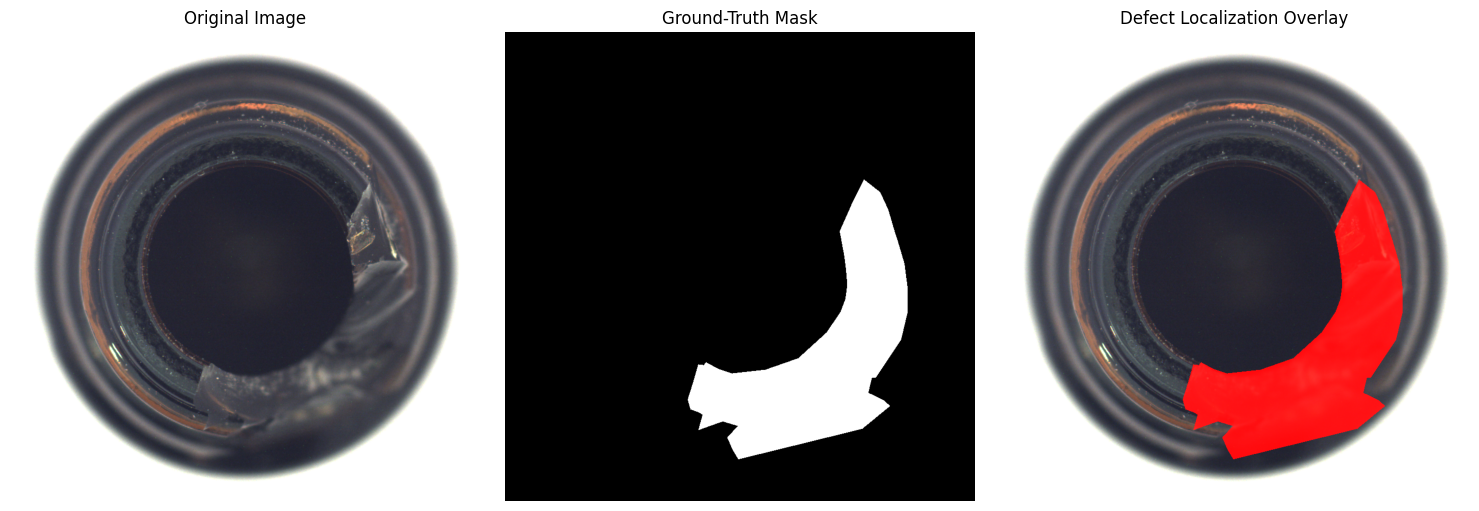

In [17]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Paths
image_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_large/000.png"
mask_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/000_mask.png"

# Load image and mask
image = Image.open(image_path).convert("RGB")
mask = Image.open(mask_path).convert("L")

# Convert to NumPy arrays
image_array = np.array(image)
mask_array = np.array(mask)

# Create a copy of the original image
overlay = image_array.copy()

# Highlight defect region
defect_pixels = mask_array > 0

# Increase red channel in defect area
overlay[defect_pixels, 0] = 255

# Reduce green and blue channels
overlay[defect_pixels, 1] = overlay[defect_pixels, 1] * 0.3
overlay[defect_pixels, 2] = overlay[defect_pixels, 2] * 0.3

# Display original, mask and overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Ground-Truth Mask")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("Defect Localization Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [18]:
import os
from PIL import Image

# Path to training images
train_good_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train/good"

# Get image files
image_files = [
    f for f in os.listdir(train_good_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

# Check dimensions of the first 10 images
print("Image dimensions:")

for file in image_files[:10]:
    image_path = os.path.join(train_good_path, file)
    image = Image.open(image_path)
    print(f"{file}: {image.size}")

Image dimensions:
173.png: (900, 900)
043.png: (900, 900)
038.png: (900, 900)
069.png: (900, 900)
083.png: (900, 900)
074.png: (900, 900)
027.png: (900, 900)
148.png: (900, 900)
177.png: (900, 900)
142.png: (900, 900)


In [19]:
from PIL import Image

image_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train/good/000.png"

image = Image.open(image_path)

print("Image size:", image.size)
print("Image mode:", image.mode)

Image size: (900, 900)
Image mode: RGB


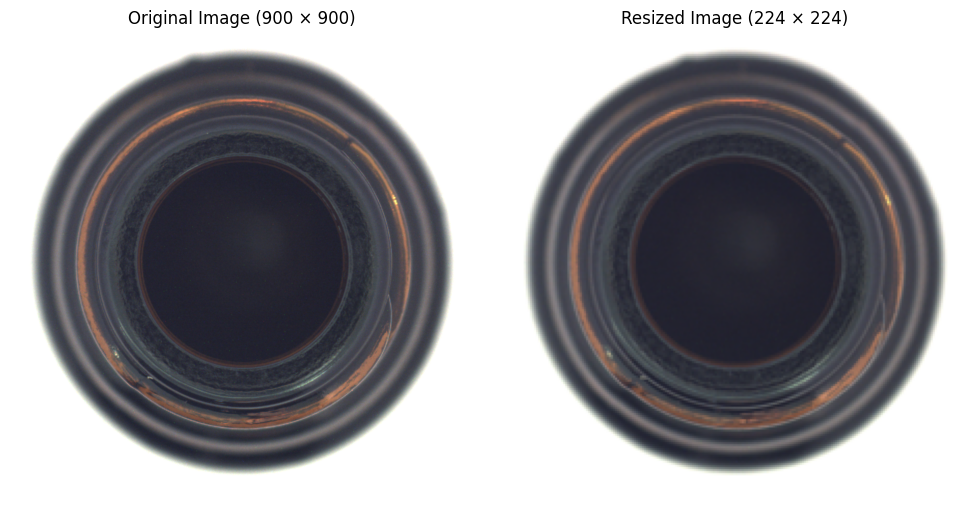

In [20]:
from PIL import Image
import matplotlib.pyplot as plt

# Original image
image_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train/good/000.png"

# Load image
image = Image.open(image_path).convert("RGB")

# Resize
resized_image = image.resize((224, 224))

# Display original and resized images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image (900 × 900)")
axes[0].axis("off")

axes[1].imshow(resized_image)
axes[1].set_title("Resized Image (224 × 224)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [21]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Load image
image_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train/good/000.png"

image = Image.open(image_path).convert("RGB")

# Resize
resized_image = image.resize((224, 224))

# Convert to NumPy array
image_array = np.array(resized_image)

print("Before normalization:")
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())
print("Data type:", image_array.dtype)

# Normalize pixel values to 0-1
normalized_image = image_array / 255.0

print("\nAfter normalization:")
print("Minimum pixel value:", normalized_image.min())
print("Maximum pixel value:", normalized_image.max())
print("Data type:", normalized_image.dtype)

Before normalization:
Minimum pixel value: 30
Maximum pixel value: 255
Data type: uint8

After normalization:
Minimum pixel value: 0.11764705882352941
Maximum pixel value: 1.0
Data type: float64


In [22]:
import os
import numpy as np
from PIL import Image

# Training data path
train_good_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train/good"

# Get all training image filenames
train_files = [
    f for f in os.listdir(train_good_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

# Sort files for consistency
train_files.sort()

print("Number of training images:", len(train_files))

# Image size for model
IMG_SIZE = 224

# Store processed images
X_train = []

for file in train_files:
    image_path = os.path.join(train_good_path, file)

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Resize
    image = image.resize((IMG_SIZE, IMG_SIZE))

    # Convert to NumPy and normalize
    image_array = np.array(image, dtype=np.float32) / 255.0

    X_train.append(image_array)

# Convert list to NumPy array
X_train = np.array(X_train, dtype=np.float32)

print("Training data shape:", X_train.shape)
print("Data type:", X_train.dtype)
print("Minimum value:", X_train.min())
print("Maximum value:", X_train.max())

Number of training images: 209
Training data shape: (209, 224, 224, 3)
Data type: float32
Minimum value: 0.10980392
Maximum value: 1.0


In [23]:
from sklearn.model_selection import train_test_split

# Split good images into training and validation sets
X_train_data, X_val_data = train_test_split(
    X_train,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train_data.shape)
print("Validation data shape:", X_val_data.shape)

Training data shape: (167, 224, 224, 3)
Validation data shape: (42, 224, 224, 3)


# Dataset Preparation

The MVTec AD dataset was used for the manufacturing defect detection project. The Bottle category was selected as the target product.

The Bottle dataset contains normal bottle images in the training set and both normal and defective bottle images in the test set. The defective categories include:

- Contamination
- Broken Large
- Broken Small

The training dataset contains 209 normal bottle images. Each image has an original resolution of 900 × 900 pixels and is represented in RGB format.

For efficient model training, the images were resized to 224 × 224 pixels and pixel values were normalized from the range 0–255 to the range 0–1.

# Training and Validation Split

The 209 normal training images were divided into:

-  80% training data: 167 images
-  20% validation data: 42 images

The validation set is used to evaluate how well the model learns the characteristics of normal bottle images without directly using the validation images during training.

In [24]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Device: cpu
Running on CPU


In [25]:
from torch.utils.data import TensorDataset, DataLoader

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train_data, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_data, dtype=torch.float32)

# Change image format:
# From (N, H, W, C)
# To   (N, C, H, W)
X_train_tensor = X_train_tensor.permute(0, 3, 1, 2)
X_val_tensor = X_val_tensor.permute(0, 3, 1, 2)

# Create datasets
train_dataset = TensorDataset(X_train_tensor)
val_dataset = TensorDataset(X_val_tensor)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 11
Validation batches: 3


In [26]:
import torch.nn as nn

class Autoencoder(nn.Module):

    def __init__(self):
        super(Autoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                256, 128,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                128, 64,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                64, 32,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 3,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)

        return decoded

In [27]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("Running on GPU")
else:
    print("Running on CPU")

Device: cpu
Running on CPU


In [28]:
model = Autoencoder().to(device)

print(model)

Autoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): ReLU()
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(128, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (5): ReLU()
    (6): ConvTranspose2d(32, 3, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (7): Sigmoid()
  )
)


## 5. Anomaly Detection Model

A Convolutional Autoencoder was selected for anomaly detection.

The model consists of two major components:

### Encoder

The encoder extracts important visual features from the input bottle image and compresses the image into a lower-dimensional representation.

### Decoder

The decoder reconstructs the original bottle image from the compressed representation.

The model is trained exclusively using normal bottle images. Therefore, it learns the visual characteristics of defect-free bottles.

During testing, defective images are expected to produce larger reconstruction errors in the regions containing defects. These reconstruction errors can subsequently be used to identify and localize manufacturing defects.

In [29]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function: MSELoss")
print("Optimizer: Adam")

Loss function: MSELoss
Optimizer: Adam


In [30]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train_data, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_data, dtype=torch.float32)

# Convert image format:
# NumPy: (N, 224, 224, 3)
# PyTorch CNN: (N, 3, 224, 224)

X_train_tensor = X_train_tensor.permute(0, 3, 1, 2)
X_val_tensor = X_val_tensor.permute(0, 3, 1, 2)

print("Training tensor shape:", X_train_tensor.shape)
print("Validation tensor shape:", X_val_tensor.shape)

# Create datasets
train_dataset = TensorDataset(X_train_tensor)
val_dataset = TensorDataset(X_val_tensor)

# Create DataLoaders
batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training tensor shape: torch.Size([167, 3, 224, 224])
Validation tensor shape: torch.Size([42, 3, 224, 224])
Training batches: 11
Validation batches: 3


In [31]:
import torch.nn as nn
import torch.optim as optim

# Reconstruction loss
criterion = nn.MSELoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [32]:
num_epochs = 30

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model.train()

    running_train_loss = 0.0

    for batch in train_loader:

        images = batch[0].to(device)

        # Forward pass
        reconstructed = model(images)

        # Calculate reconstruction loss
        loss = criterion(reconstructed, images)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)
    train_losses.append(train_loss)

    # --------------------
    # Validation
    # --------------------
    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for batch in val_loader:

            images = batch[0].to(device)

            reconstructed = model(images)

            loss = criterion(reconstructed, images)

            running_val_loss += loss.item()

    val_loss = running_val_loss / len(val_loader)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )

Epoch [1/30] Train Loss: 0.123505 Val Loss: 0.094969
Epoch [2/30] Train Loss: 0.063617 Val Loss: 0.036745
Epoch [3/30] Train Loss: 0.031085 Val Loss: 0.018900
Epoch [4/30] Train Loss: 0.015549 Val Loss: 0.011959
Epoch [5/30] Train Loss: 0.009719 Val Loss: 0.008037
Epoch [6/30] Train Loss: 0.006856 Val Loss: 0.006079
Epoch [7/30] Train Loss: 0.005517 Val Loss: 0.005075
Epoch [8/30] Train Loss: 0.004782 Val Loss: 0.004507
Epoch [9/30] Train Loss: 0.004206 Val Loss: 0.003922
Epoch [10/30] Train Loss: 0.003642 Val Loss: 0.003366
Epoch [11/30] Train Loss: 0.003116 Val Loss: 0.002954
Epoch [12/30] Train Loss: 0.002808 Val Loss: 0.002787
Epoch [13/30] Train Loss: 0.002698 Val Loss: 0.002694
Epoch [14/30] Train Loss: 0.002626 Val Loss: 0.002636
Epoch [15/30] Train Loss: 0.002560 Val Loss: 0.002592
Epoch [16/30] Train Loss: 0.002521 Val Loss: 0.002527
Epoch [17/30] Train Loss: 0.002467 Val Loss: 0.002497
Epoch [18/30] Train Loss: 0.002427 Val Loss: 0.002452
Epoch [19/30] Train Loss: 0.002402 Va

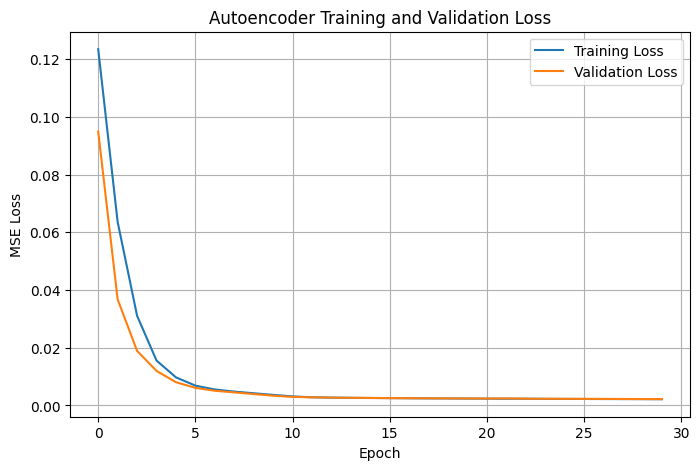

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [34]:
# Calculate reconstruction errors for validation images

model.eval()

reconstruction_errors = []

with torch.no_grad():
    for batch in val_loader:
        images = batch[0].to(device)

        reconstructed = model(images)

        # Calculate MSE for each image
        errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=(1, 2, 3)
        )

        reconstruction_errors.extend(errors.cpu().numpy())

print("Number of validation images:", len(reconstruction_errors))
print("Minimum reconstruction error:", min(reconstruction_errors))
print("Maximum reconstruction error:", max(reconstruction_errors))
print("Mean reconstruction error:", sum(reconstruction_errors) / len(reconstruction_errors))

Number of validation images: 42
Minimum reconstruction error: 0.0016532032
Maximum reconstruction error: 0.0028688167
Mean reconstruction error: 0.0021755346


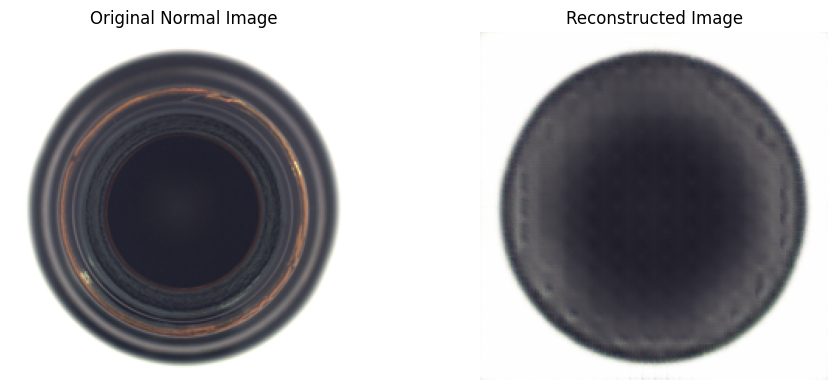

In [35]:
import matplotlib.pyplot as plt

# Get one batch from validation data
model.eval()

with torch.no_grad():
    batch = next(iter(val_loader))
    images = batch[0].to(device)

    reconstructed = model(images)

# Select first image
original = images[0].cpu().permute(1, 2, 0).numpy()
reconstruction = reconstructed[0].cpu().permute(1, 2, 0).numpy()

# Display original and reconstructed image
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Normal Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstruction)
plt.title("Reconstructed Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [36]:
# Test one contamination image

import os
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch

contamination_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/contamination"

# Get the first contamination image
contamination_files = [
    f for f in os.listdir(contamination_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

test_file = contamination_files[0]
test_image_path = os.path.join(contamination_path, test_file)

# Load and preprocess the image
test_image = Image.open(test_image_path).convert("RGB")
test_image = test_image.resize((224, 224))

test_array = np.array(test_image, dtype=np.float32) / 255.0

# Convert to PyTorch tensor
test_tensor = torch.tensor(test_array).permute(2, 0, 1).unsqueeze(0).to(device)

# Reconstruct using the autoencoder
model.eval()

with torch.no_grad():
    reconstructed = model(test_tensor)

# Calculate reconstruction error
error = torch.mean((test_tensor - reconstructed) ** 2).item()

print("Test image:", test_file)
print("Reconstruction error:", error)

Test image: 007.png
Reconstruction error: 0.004802274983376265


In [37]:
# Test one broken-large image

broken_large_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_large"

broken_large_files = [
    f for f in os.listdir(broken_large_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

test_file = broken_large_files[0]
test_image_path = os.path.join(broken_large_path, test_file)

# Load and preprocess
test_image = Image.open(test_image_path).convert("RGB")
test_image = test_image.resize((224, 224))

test_array = np.array(test_image, dtype=np.float32) / 255.0

# Convert to tensor
test_tensor = torch.tensor(test_array).permute(2, 0, 1).unsqueeze(0).to(device)

# Reconstruct
model.eval()

with torch.no_grad():
    reconstructed = model(test_tensor)

# Calculate reconstruction error
error = torch.mean((test_tensor - reconstructed) ** 2).item()

print("Test image:", test_file)
print("Reconstruction error:", error)

Test image: 007.png
Reconstruction error: 0.0022275142837315798


In [38]:
# Test one broken-small image

broken_small_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_small"

broken_small_files = [
    f for f in os.listdir(broken_small_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

test_file = broken_small_files[0]
test_image_path = os.path.join(broken_small_path, test_file)

# Load and preprocess
test_image = Image.open(test_image_path).convert("RGB")
test_image = test_image.resize((224, 224))

test_array = np.array(test_image, dtype=np.float32) / 255.0

# Convert to tensor
test_tensor = torch.tensor(test_array).permute(2, 0, 1).unsqueeze(0).to(device)

# Reconstruct
model.eval()

with torch.no_grad():
    reconstructed = model(test_tensor)

# Calculate reconstruction error
error = torch.mean((test_tensor - reconstructed) ** 2).item()

print("Test image:", test_file)
print("Reconstruction error:", error)

Test image: 007.png
Reconstruction error: 0.0027950620278716087


In [39]:
# Calculate anomaly detection threshold from normal validation images

import numpy as np

reconstruction_errors = np.array(reconstruction_errors)

mean_error = reconstruction_errors.mean()
std_error = reconstruction_errors.std()

# Threshold = mean + 3 standard deviations
threshold = mean_error + 3 * std_error

print("Mean reconstruction error:", mean_error)
print("Standard deviation:", std_error)
print("Anomaly threshold:", threshold)

Mean reconstruction error: 0.0021755346
Standard deviation: 0.0002788973
Anomaly threshold: 0.0030122264


In [40]:
# Calculate reconstruction errors for all test images

test_categories = ["good", "contamination", "broken_large", "broken_small"]

all_results = []

for category in test_categories:

    category_path = f"/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/{category}"

    files = [
        f for f in os.listdir(category_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    for file in files:

        image_path = os.path.join(category_path, file)

        # Load and preprocess
        image = Image.open(image_path).convert("RGB")
        image = image.resize((224, 224))

        image_array = np.array(image, dtype=np.float32) / 255.0

        # Convert to tensor
        image_tensor = torch.tensor(
            image_array
        ).permute(2, 0, 1).unsqueeze(0).to(device)

        # Reconstruct
        model.eval()

        with torch.no_grad():
            reconstructed = model(image_tensor)

        # Reconstruction error
        error = torch.mean(
            (image_tensor - reconstructed) ** 2
        ).item()

        # Classification
        prediction = "Anomaly" if error > threshold else "Normal"

        all_results.append({
            "category": category,
            "file": file,
            "error": error,
            "prediction": prediction
        })

print("Total test images:", len(all_results))

Total test images: 83


In [41]:
# Count predictions
normal_count = sum(
    1 for result in all_results
    if result["prediction"] == "Normal"
)

anomaly_count = sum(
    1 for result in all_results
    if result["prediction"] == "Anomaly"
)

print("Total test images:", len(all_results))
print("Predicted Normal:", normal_count)
print("Predicted Anomaly:", anomaly_count)

Total test images: 83
Predicted Normal: 67
Predicted Anomaly: 16


In [44]:
from collections import Counter

category_results = {}

for result in all_results:
    category = result["category"]
    
    if category not in category_results:
        category_results[category] = []
    
    category_results[category].append(result["prediction"])

print("Prediction results by category:\n")

for category, predictions in category_results.items():
    counts = Counter(predictions)
    
    print(f"{category}:")
    print(f"  Normal  : {counts.get('Normal', 0)}")
    print(f"  Anomaly : {counts.get('Anomaly', 0)}")

Prediction results by category:

good:
  Normal  : 20
  Anomaly : 0
contamination:
  Normal  : 15
  Anomaly : 6
broken_large:
  Normal  : 16
  Anomaly : 4
broken_small:
  Normal  : 16
  Anomaly : 6


In [45]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Create actual and predicted labels
y_true = []
y_pred = []

for result in all_results:
    # Good = Normal, all defective categories = Anomaly
    actual = 0 if result["category"] == "good" else 1
    predicted = 0 if result["prediction"] == "Normal" else 1
    
    y_true.append(actual)
    y_pred.append(predicted)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print("Anomaly Detection Performance")
print("--------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Anomaly Detection Performance
--------------------------------
Accuracy : 0.4337
Precision: 1.0000
Recall   : 0.2540
F1 Score : 0.4051

Confusion Matrix:
[[20  0]
 [47 16]]


In [46]:
# Analyze reconstruction errors by defect category

from collections import defaultdict
import numpy as np

errors_by_category = defaultdict(list)

for result in all_results:
    errors_by_category[result["category"]].append(result["error"])

print("Reconstruction Error by Category")
print("----------------------------------")

for category, errors in errors_by_category.items():
    print(f"\n{category}")
    print(f"  Count : {len(errors)}")
    print(f"  Mean  : {np.mean(errors):.6f}")
    print(f"  Min   : {np.min(errors):.6f}")
    print(f"  Max   : {np.max(errors):.6f}")

Reconstruction Error by Category
----------------------------------

good
  Count : 20
  Mean  : 0.002375
  Min   : 0.001704
  Max   : 0.002954

contamination
  Count : 21
  Mean  : 0.002586
  Min   : 0.001499
  Max   : 0.004802

broken_large
  Count : 20
  Mean  : 0.002671
  Min   : 0.001952
  Max   : 0.003875

broken_small
  Count : 22
  Mean  : 0.002816
  Min   : 0.001925
  Max   : 0.004363


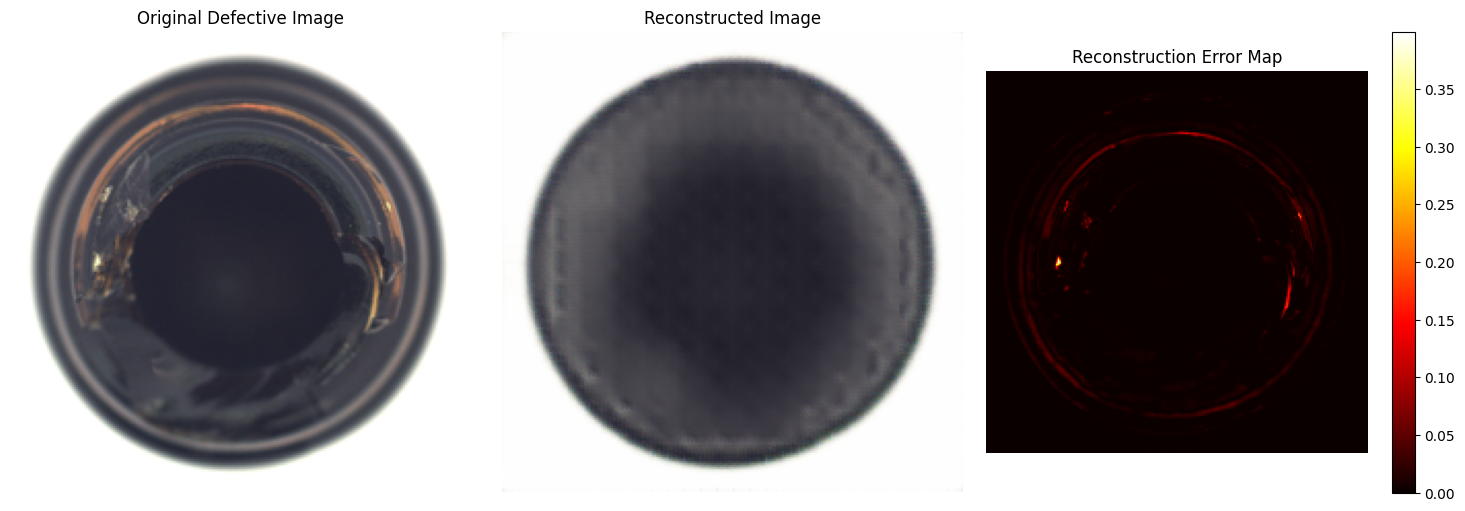

In [47]:
# Visualize reconstruction error map for one defective image

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch

# Select one broken-large image
broken_large_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_large"

files = [
    f for f in os.listdir(broken_large_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

test_file = files[0]
image_path = os.path.join(broken_large_path, test_file)

# Load and preprocess
image = Image.open(image_path).convert("RGB")
image = image.resize((224, 224))

image_array = np.array(image, dtype=np.float32) / 255.0

# Convert to tensor
image_tensor = torch.tensor(
    image_array
).permute(2, 0, 1).unsqueeze(0).to(device)

# Reconstruct
model.eval()

with torch.no_grad():
    reconstructed = model(image_tensor)

# Calculate pixel-wise reconstruction error
error_map = torch.mean(
    (image_tensor - reconstructed) ** 2,
    dim=1
).squeeze().cpu().numpy()

# Get reconstructed image
reconstructed_image = (
    reconstructed.squeeze()
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_array)
plt.title("Original Defective Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reconstructed_image)
plt.title("Reconstructed Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(error_map, cmap="hot")
plt.title("Reconstruction Error Map")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

In [48]:
# Use maximum reconstruction error from normal validation images
threshold = max(reconstruction_errors)

print("New anomaly threshold:", threshold)

# Recalculate predictions
for result in all_results:
    if result["error"] > threshold:
        result["prediction"] = "Anomaly"
    else:
        result["prediction"] = "Normal"

# Count predictions
normal_count = sum(
    1 for result in all_results
    if result["prediction"] == "Normal"
)

anomaly_count = sum(
    1 for result in all_results
    if result["prediction"] == "Anomaly"
)

print("Total test images:", len(all_results))
print("Predicted Normal:", normal_count)
print("Predicted Anomaly:", anomaly_count)

New anomaly threshold: 0.0028688167
Total test images: 83
Predicted Normal: 59
Predicted Anomaly: 24


In [49]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Create actual and predicted labels
y_true = []
y_pred = []

for result in all_results:
    # good = normal, defective categories = anomaly
    actual = 0 if result["category"] == "good" else 1
    predicted = 0 if result["prediction"] == "Normal" else 1

    y_true.append(actual)
    y_pred.append(predicted)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print("Updated Anomaly Detection Performance")
print("--------------------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Updated Anomaly Detection Performance
--------------------------------------
Accuracy  : 0.5060
Precision : 0.9583
Recall    : 0.3651
F1 Score  : 0.5287

Confusion Matrix:
[[19  1]
 [40 23]]


In [50]:
# Compare different anomaly thresholds

thresholds = [
    0.0015,
    0.0018,
    0.0020,
    0.0022,
    0.0025,
    0.0026888167
]

print("Threshold Comparison")
print("-" * 70)

for threshold_value in thresholds:

    y_true_temp = []
    y_pred_temp = []

    for result in all_results:
        actual = 0 if result["category"] == "good" else 1
        predicted = 1 if result["error"] > threshold_value else 0

        y_true_temp.append(actual)
        y_pred_temp.append(predicted)

    accuracy = accuracy_score(y_true_temp, y_pred_temp)
    precision = precision_score(y_true_temp, y_pred_temp, zero_division=0)
    recall = recall_score(y_true_temp, y_pred_temp, zero_division=0)
    f1 = f1_score(y_true_temp, y_pred_temp, zero_division=0)

    print(
        f"Threshold: {threshold_value:.7f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold Comparison
----------------------------------------------------------------------
Threshold: 0.0015000 | Accuracy: 0.7470 | Precision: 0.7561 | Recall: 0.9841 | F1: 0.8552
Threshold: 0.0018000 | Accuracy: 0.7349 | Precision: 0.7595 | Recall: 0.9524 | F1: 0.8451
Threshold: 0.0020000 | Accuracy: 0.6988 | Precision: 0.7568 | Recall: 0.8889 | F1: 0.8175
Threshold: 0.0022000 | Accuracy: 0.6627 | Precision: 0.7692 | Recall: 0.7937 | F1: 0.7812
Threshold: 0.0025000 | Accuracy: 0.5542 | Precision: 0.8250 | Recall: 0.5238 | F1: 0.6408
Threshold: 0.0026888 | Accuracy: 0.5301 | Precision: 0.9000 | Recall: 0.4286 | F1: 0.5806


In [51]:
# Set the selected anomaly detection threshold
threshold = 0.0015

# Recalculate predictions using the selected threshold
for result in all_results:
    if result["error"] > threshold:
        result["prediction"] = "Anomaly"
    else:
        result["prediction"] = "Normal"

# Count predictions
normal_count = sum(
    1 for result in all_results
    if result["prediction"] == "Normal"
)

anomaly_count = sum(
    1 for result in all_results
    if result["prediction"] == "Anomaly"
)

print("Selected anomaly threshold:", threshold)
print("Total test images:", len(all_results))
print("Predicted Normal:", normal_count)
print("Predicted Anomaly:", anomaly_count)

Selected anomaly threshold: 0.0015
Total test images: 83
Predicted Normal: 1
Predicted Anomaly: 82


In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

y_true = []
y_pred = []

for result in all_results:
    actual = 0 if result["category"] == "good" else 1
    predicted = 0 if result["prediction"] == "Normal" else 1

    y_true.append(actual)
    y_pred.append(predicted)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print("FINAL ANOMALY DETECTION PERFORMANCE")
print("------------------------------------")
print(f"Threshold : {threshold}")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

FINAL ANOMALY DETECTION PERFORMANCE
------------------------------------
Threshold : 0.0015
Accuracy  : 0.7470
Precision : 0.7561
Recall    : 0.9841
F1 Score  : 0.8552

Confusion Matrix:
[[ 0 20]
 [ 1 62]]


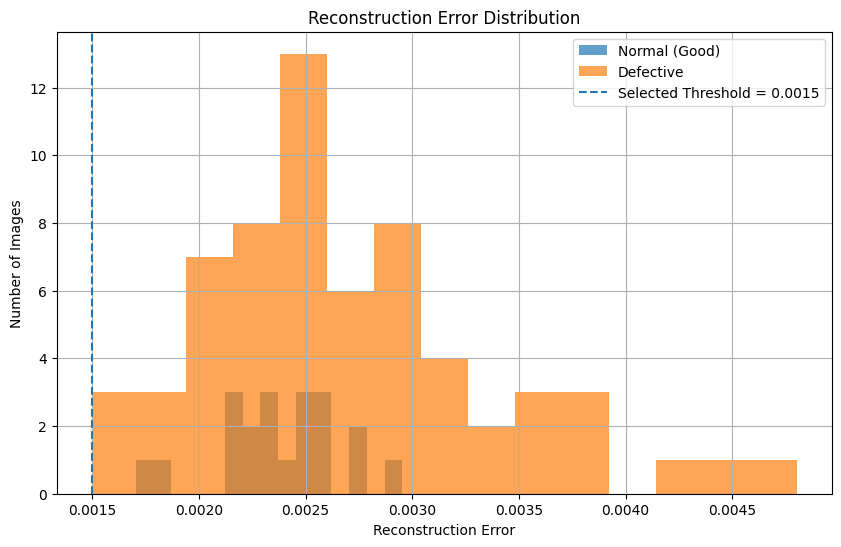

In [53]:
import matplotlib.pyplot as plt

good_errors = [
    result["error"]
    for result in all_results
    if result["category"] == "good"
]

defect_errors = [
    result["error"]
    for result in all_results
    if result["category"] != "good"
]

plt.figure(figsize=(10, 6))

plt.hist(good_errors, bins=15, alpha=0.7, label="Normal (Good)")
plt.hist(defect_errors, bins=15, alpha=0.7, label="Defective")

plt.axvline(
    threshold,
    linestyle="--",
    label=f"Selected Threshold = {threshold}"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Reconstruction Error Distribution")
plt.legend()
plt.grid(True)

plt.show()

In [55]:
import numpy as np
from sklearn.metrics import balanced_accuracy_score

# Get all reconstruction errors
errors = np.array([result["error"] for result in all_results])

# Actual labels: 0 = normal, 1 = defective
y_true = np.array([
    0 if result["category"] == "good" else 1
    for result in all_results
])

best_threshold = None
best_balanced_accuracy = 0

# Test many possible thresholds
for threshold_value in np.linspace(errors.min(), errors.max(), 200):

    y_pred_temp = (errors > threshold_value).astype(int)

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred_temp
    )

    if balanced_acc > best_balanced_accuracy:
        best_balanced_accuracy = balanced_acc
        best_threshold = threshold_value

print("Best threshold:", best_threshold)
print("Best balanced accuracy:", best_balanced_accuracy)

Best threshold: 0.0027604930391815965
Best balanced accuracy: 0.6813492063492064


In [ ]:
# Evaluate the automatically selected threshold

threshold = best_threshold

y_pred = (errors > threshold).astype(int)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print("PERFORMANCE AT BEST BALANCED-ACCURACY THRESHOLD")
print("-----------------------------------------------")
print(f"Threshold : {threshold:.7f}")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

In [57]:
# Evaluate the automatically selected threshold

threshold = best_threshold

y_pred = (errors > threshold).astype(int)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print("PERFORMANCE AT BEST BALANCED-ACCURACY THRESHOLD")
print("-----------------------------------------------")
print(f"Threshold : {threshold:.7f}")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

PERFORMANCE AT BEST BALANCED-ACCURACY THRESHOLD
-----------------------------------------------
Threshold : 0.0027605
Accuracy  : 0.5422
Precision : 0.9630
Recall    : 0.4127
F1 Score  : 0.5778

Confusion Matrix:
[[19  1]
 [37 26]]


In [59]:
print("RECONSTRUCTION ERROR COMPARISON")
print("--------------------------------")

print(f"Normal images:")
print(f"  Mean : {np.mean(good_errors):.7f}")
print(f"  Std  : {np.std(good_errors):.7f}")
print(f"  Min  : {np.min(good_errors):.7f}")
print(f"  Max  : {np.max(good_errors):.7f}")

print("\nDefective images:")
print(f"  Mean : {np.mean(defect_errors):.7f}")
print(f"  Std  : {np.std(defect_errors):.7f}")
print(f"  Min  : {np.min(defect_errors):.7f}")
print(f"  Max  : {np.max(defect_errors):.7f}")

RECONSTRUCTION ERROR COMPARISON
--------------------------------
Normal images:
  Mean : 0.0023749
  Std  : 0.0002929
  Min  : 0.0017044
  Max  : 0.0029538

Defective images:
  Mean : 0.0026934
  Std  : 0.0006732
  Min  : 0.0014989
  Max  : 0.0048023


In [5]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cpu


In [6]:
import torch
import torchvision
from torchvision.models import resnet18, ResNet18_Weights

# Load pretrained ResNet18
weights = ResNet18_Weights.DEFAULT
resnet = resnet18(weights=weights)

# Remove the final classification layer
feature_extractor = torch.nn.Sequential(*list(resnet.children())[:-2])

feature_extractor = feature_extractor.to(device)
feature_extractor.eval()

# Image preprocessing used by ImageNet pretrained ResNet
resnet_transform = weights.transforms()

print("ResNet18 feature extractor loaded successfully.")
print("Device:", device)

ResNet18 feature extractor loaded successfully.
Device: cpu


In [7]:
from PIL import Image
import torch
import matplotlib.pyplot as plt

# Use one normal training image
image_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train/good/000.png"

# Load image
image = Image.open(image_path).convert("RGB")

# Apply ResNet preprocessing
input_tensor = resnet_transform(image).unsqueeze(0).to(device)

# Extract features
with torch.no_grad():
    features = feature_extractor(input_tensor)

print("Input shape:", input_tensor.shape)
print("Feature shape:", features.shape)

Input shape: torch.Size([1, 3, 224, 224])
Feature shape: torch.Size([1, 512, 7, 7])


In [8]:
import os
import numpy as np
from PIL import Image
import torch

train_good_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train/good"

feature_list = []
image_names = []

feature_extractor.eval()

for file in sorted(os.listdir(train_good_path)):
    if file.lower().endswith((".png", ".jpg", ".jpeg")):

        image_path = os.path.join(train_good_path, file)

        image = Image.open(image_path).convert("RGB")
        input_tensor = resnet_transform(image).unsqueeze(0).to(device)

        with torch.no_grad():
            features = feature_extractor(input_tensor)

        feature_list.append(features.cpu().numpy())
        image_names.append(file)

# Convert to NumPy array
normal_features = np.concatenate(feature_list, axis=0)

print("Number of images:", len(image_names))
print("Feature array shape:", normal_features.shape)

Number of images: 209
Feature array shape: (209, 512, 7, 7)


In [9]:
# Create a reference representation of normal bottle features
normal_feature_mean = np.mean(normal_features, axis=0)

print("Normal feature reference shape:", normal_feature_mean.shape)
print("Minimum feature value:", normal_feature_mean.min())
print("Maximum feature value:", normal_feature_mean.max())

Normal feature reference shape: (512, 7, 7)
Minimum feature value: 0.0
Maximum feature value: 15.544619


In [10]:
# Extract features from one normal bottle image
test_image = Image.open(image_path).convert("RGB")
test_tensor = resnet_transform(test_image).unsqueeze(0).to(device)

with torch.no_grad():
    test_features = feature_extractor(test_tensor)

# Calculate feature distance from normal reference
feature_distance = torch.mean(
    (test_features.squeeze(0).cpu() - normal_feature_mean) ** 2
).item()

print("Feature distance from normal reference:", feature_distance)

Feature distance from normal reference: 0.07607113569974899


/tmp/ipykernel_50/3672446301.py:10: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  (test_features.squeeze(0).cpu() - normal_feature_mean) ** 2


In [13]:
# Calculate feature distances of normal images from the normal reference

normal_distances = []

for features in normal_features:
    distance = np.mean(
        (features - normal_feature_mean) ** 2
    )
    normal_distances.append(distance)

normal_distances = np.array(normal_distances)

print("Normal feature distance statistics")
print("-----------------------------------")
print("Mean:", normal_distances.mean())
print("Std:", normal_distances.std())
print("Minimum:", normal_distances.min())
print("Maximum:", normal_distances.max())

Normal feature distance statistics
-----------------------------------
Mean: 0.12284988
Std: 0.048765086
Minimum: 0.063931055
Maximum: 0.33470958
